# P5. Deteksi Tepi dan Keputusan Pemakaiannya
**Praktikum P5-P6 Computer Vision, studi kasus SIMUTEH** | Teknik Informatika UMMI

Isi notebook: **Bagian 1** (gradien, Sobel, Prewitt, LoG, Canny, perbandingan operator) dan **Bagian 2** (parameter Canny, ambang otomatis, tepi pada daun sehat, keputusan pemakaian tepi).

In [2]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [3]:
# ===== Cek prasyarat dari Evaluasi P1-P4 =====
wajib = ["../src/utils_cv.py", "../src/praproses.py",
         "../hasil/param_praproses.json", "../data/sintetis/label.csv"]
hilang = [p for p in wajib if not os.path.exists(p)]
assert not hilang, f"Belum ada: {hilang}. Jalankan B1-B5 (Run all) di akun dan folder yang sama dulu."
assert len(os.listdir("../data/sintetis/citra")) == 60, "Dataset harus berisi 60 citra (SEED 1007)."
print("Prasyarat dari B1-B5 lengkap.")

Prasyarat dari B1-B5 lengkap.


## 0. Kode awal `utils_tepi.py` dan impor
Berkas ini kode awal dari petunjuk (Lampiran A): `tepi_acuan`, `skor_tepi`, `iou`, `mask_daun_awal`, `bercak_awal`.

In [4]:
%%writefile ../src/utils_tepi.py
"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi (P5-P6 SIMUTEH)."""
import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner (255 = objek)."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255


def skor_tepi(prediksi, acuan, toleransi=2):
    """Presisi, recall, dan F1 tepi dengan toleransi jarak (piksel).
    Presisi: porsi piksel tepi prediksi yang berjarak <= toleransi dari tepi acuan.
    Recall : porsi piksel tepi acuan yang berjarak <= toleransi dari tepi prediksi."""
    p = prediksi > 0
    a = acuan > 0
    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0
    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)
    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara: ambang Otsu pada kanal saturasi (dibahas tuntas di P7)."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Citra biner bercak sementara: piksel daun pada kanal terpilih yang lebih
    terang dari median daun + k x MAD (simpangan median absolut, dikali 1,4826).
    Median dan MAD dipakai karena tidak ikut terseret oleh bercak yang luas.
    Hasilnya sengaja masih kasar: memuat titik derau, potongan tulang daun,
    dan tepi daun yang harus dibersihkan dengan operasi morfologi (P6)."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0
    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)

Writing ../src/utils_tepi.py


In [5]:
# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))    # praproses final dari Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")
berbercak = label[label.kelas != "sehat"]                    # 40 citra berbercak
URUTAN = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

# Semua 60 citra dimuat dan dipraproses SEKALI, lalu dipakai ulang oleh seluruh eksperimen
DATA = {}
for nama in label.nama_file:
    img, md, mb = muat(nama)
    D = dict(img=img, md=md, mb=mb, pra=praproses(img, PARAM),
             ac_daun=tepi_acuan(md), ac_bercak=tepi_acuan(mb))
    D["ac"] = cv2.bitwise_or(D["ac_daun"], D["ac_bercak"])   # tepi acuan daun + bercak
    DATA[nama] = D
print(len(DATA), "citra siap | praproses:", PARAM)

60 citra siap | praproses: {'lebar': 640, 'gamma': 'auto', 'gamma_terang': 1.6, 'gamma_gelap': 1.0, 'clahe_clip': 1.0, 'clahe_tile': 4, 'clahe_otomatis': True, 'batas_tidak_rata': 0.65, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


## Bagian 1. Gradien citra dan operator tepi

### Langkah 1.2 Persiapan dan gradien Sobel

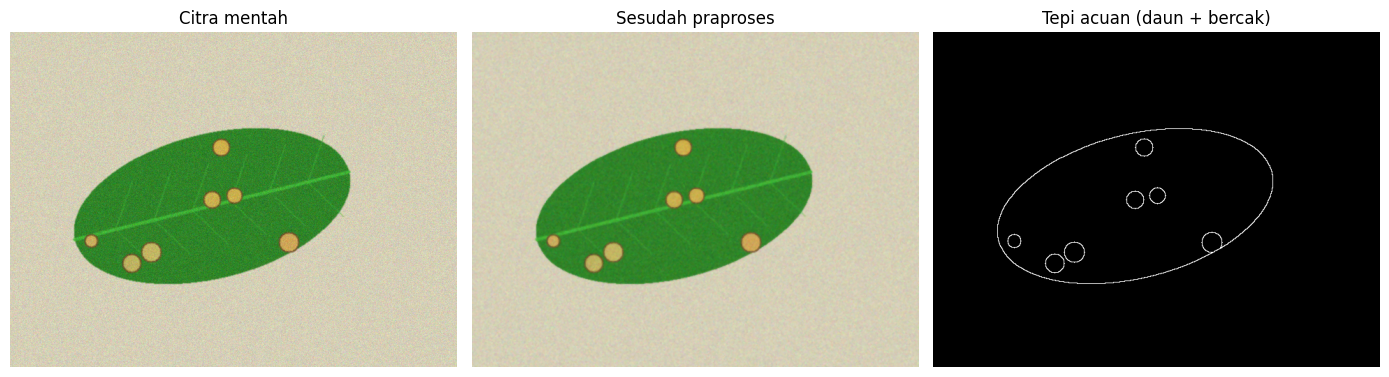

In [6]:
D = DATA["teh_041.png"]
img, pra, acuan = D["img"], D["pra"], D["ac"]
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])
plt.show()

selisih maks gx manual vs cv2.Sobel: 0.0
selisih maks gy manual vs cv2.Sobel: 0.0
magnitudo maks: 595.2


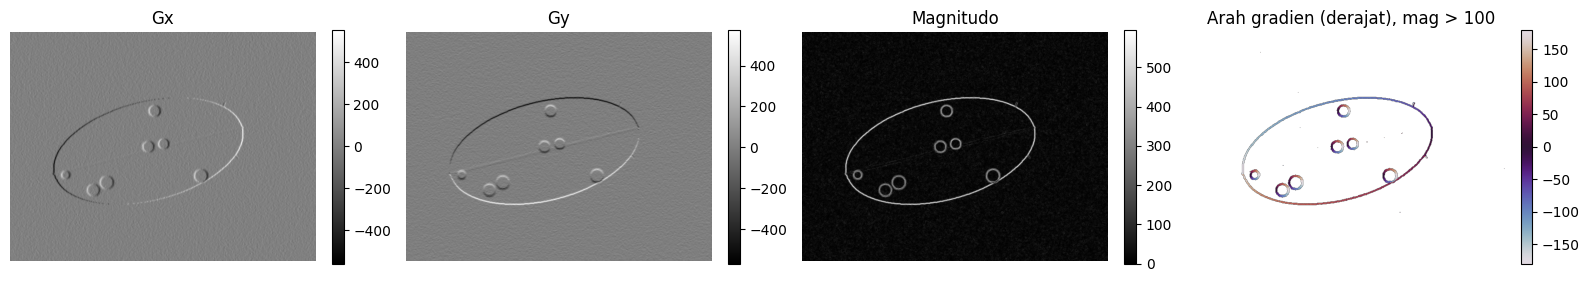

In [7]:
# Gradien Sobel dihitung manual dengan kernel sendiri, lalu dicek terhadap cv2.Sobel
g = pra[:, :, 2].astype(np.float32)                 # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx)                # turunan arah x -> merespons tepi vertikal
gy = cv2.filter2D(g, cv2.CV_32F, ky)                # turunan arah y -> merespons tepi horizontal
mag  = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)).max())
print("selisih maks gy manual vs cv2.Sobel:", np.abs(gy - cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)).max())
print("magnitudo maks:", mag.max().round(1))

# panel arah hanya menampilkan piksel yang gradiennya berarti (mag > 100); di area rata arahnya tak bermakna
arah_tampil = np.ma.masked_where(mag <= 100, arah)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (c, jd, cm) in zip(ax, [(gx, "Gx", "gray"), (gy, "Gy", "gray"), (mag, "Magnitudo", "gray"),
                               (arah_tampil, "Arah gradien (derajat), mag > 100", "twilight")]):
    h = a.imshow(c, cmap=cm); a.set_title(jd); a.axis("off"); fig.colorbar(h, ax=a, fraction=0.035)
plt.tight_layout(); plt.savefig("../hasil/p5_gradien.png", dpi=120); plt.show()

### Langkah 1.3 Empat operator pada satu citra

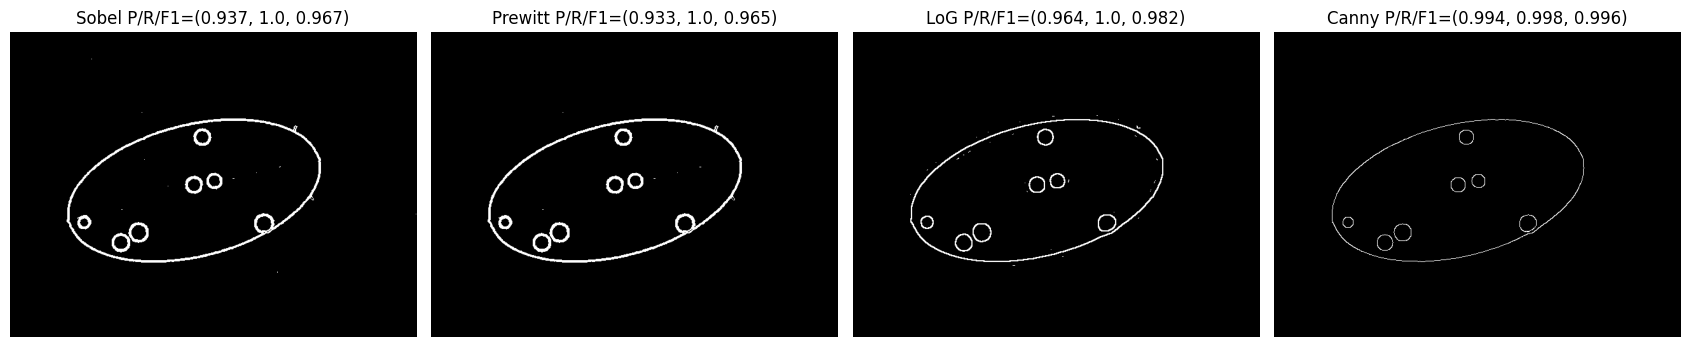

In [8]:
KX_SOBEL   = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
KX_PREWITT = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)

def _magnitudo(g, kx):
    """Magnitudo gradien dari kernel arah-x (kernel arah-y = transposnya)."""
    g = g.astype(np.float32)
    return np.hypot(cv2.filter2D(g, cv2.CV_32F, kx), cv2.filter2D(g, cv2.CV_32F, kx.T))

def tepi_sobel(g, T=100):
    return ((_magnitudo(g, KX_SOBEL) > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    return ((_magnitudo(g, KX_PREWITT) > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """LoG: tepi = perlintasan nol (min < 0 < maks di jendela 3x3) yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    se = np.ones((3, 3), np.uint8)
    terkecil, terbesar = cv2.erode(L, se), cv2.dilate(L, se)
    lintas_nol = (terkecil < 0) & (terbesar > 0)
    cukup_kuat = (terbesar - terkecil) > frac * np.abs(L).max()
    return ((lintas_nol & cukup_kuat) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}

g = DATA["teh_041.png"]["pra"][:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, DATA['teh_041.png']['ac'])}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))
plt.savefig("../hasil/p5_empat_operator.png", dpi=120); plt.show()

### Langkah 1.4 Perbandingan menyeluruh (40 citra berbercak)

In [9]:
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    for sumber, im in {"mentah": D["img"], "praproses": D["pra"]}.items():
        kanal = {"Gray": cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), "R": im[:, :, 2]}
        for kn, g in kanal.items():
            for mn, f in metode.items():
                p, r, f1 = skor_tepi(f(g), D["ac"])
                baris.append([d.kondisi_cahaya, sumber, kn, mn, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
display(ringkas)

# Tabel 6: rerata F1 (baris = operator, kolom = sumber + kanal)
kolom6 = [("mentah", "Gray"), ("mentah", "R"), ("praproses", "Gray"), ("praproses", "R")]
tab6 = ringkas["F1"].unstack(["sumber", "kanal"]).loc[list(metode), kolom6]
tab6.index = ["Sobel (T = 100)", "Prewitt (T = 75)", "LoG (sigma 3)", "Canny (30/90, sigma 2)"]
tab6.columns = ["Mentah, Gray", "Mentah, R", "Praproses, Gray", "Praproses, R"]
print("Tabel 6: rerata F1 tepi"); display(tab6)
tab6.to_csv("../hasil/p5_tabel6_f1.csv")

P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.740  0.749  0.742
                LoG      0.629  0.996  0.768
                Prewitt  0.837  0.952  0.881
                Sobel    0.819  0.961  0.875
          R     Canny    0.988  0.966  0.975
                LoG      0.915  0.997  0.949
                Prewitt  0.688  0.994  0.779
                Sobel    0.630  0.995  0.726
praproses Gray  Canny    0.740  0.751  0.744
                LoG      0.630  0.996  0.769
                Prewitt  0.872  0.822  0.775
                Sobel    0.869  0.834  0.789
          R     Canny    0.986  0.957  0.968
                LoG      0.919  0.997  0.952
                Prewitt  0.937  0.978  0.955
                Sobel    0.932  0.981  0.953

Tabel 6: rerata F1 tepi


,"Mentah, Gray","Mentah, R","Praproses, Gray","Praproses, R"
Sobel (T = 100),0.875,0.726,0.789,0.953
Prewitt (T = 75),0.881,0.779,0.775,0.955
LoG (sigma 3),0.768,0.949,0.769,0.952
"Canny (30/90, sigma 2)",0.742,0.975,0.744,0.968


### Langkah 1.5 Grafik F1 per kondisi cahaya (kanal R, sesudah praproses)

metode,Sobel,Prewitt,LoG,Canny
kondisi,,,,
normal,0.975,0.974,0.979,0.990
gelap,0.953,0.949,0.985,0.990
terang,0.952,0.961,0.985,0.989
kontras_rendah,0.954,0.948,0.862,0.886
bayangan,0.931,0.944,0.951,0.987


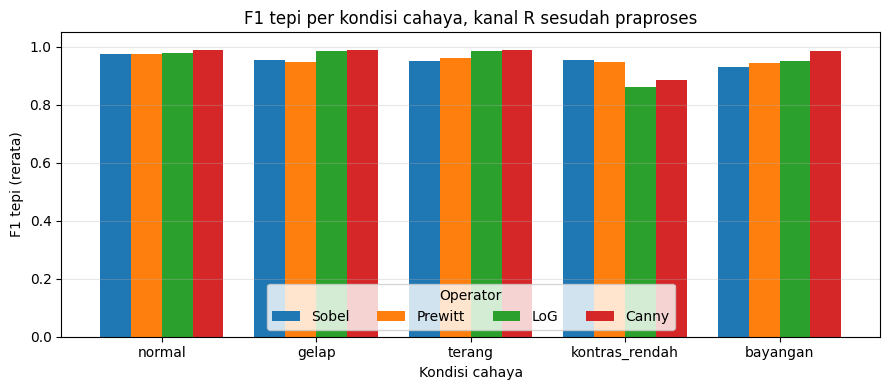

In [10]:
f1_kondisi = (tabel_tepi.query("sumber == 'praproses' and kanal == 'R'")
              .pivot_table(index="kondisi", columns="metode", values="F1")
              .reindex(URUTAN)[list(metode)])
display(f1_kondisi.round(3))

ax = f1_kondisi.plot.bar(figsize=(9, 4), width=0.8, rot=0)
ax.set_ylabel("F1 tepi (rerata)"); ax.set_xlabel("Kondisi cahaya"); ax.set_ylim(0, 1.05)
ax.set_title("F1 tepi per kondisi cahaya, kanal R sesudah praproses")
ax.legend(title="Operator", ncol=4, loc="lower center"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("../hasil/p5_f1_kondisi.png", dpi=120); plt.show()

## Bagian 2. Algoritma Canny dan keputusan pemakaian tepi

### Langkah 2.2 Pengaruh sigma dan ambang Canny (kanal R sesudah praproses)
`R_bercak` adalah recall khusus tepi bercak: bila turun, bercak kecil ikut hilang.

In [11]:
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    g = D["pra"][:, :, 2]
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, D["ac"])
            r_bercak = skor_tepi(e, D["ac_bercak"])[1]
            baris.append([d.kelas, sigma, f"{lo}/{hi}", p, r, f1, r_bercak])
canny = pd.DataFrame(baris, columns=["kelas", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
canny.to_csv("../hasil/p5_canny_eksperimen_raw.csv", index=False)

urut7 = pd.MultiIndex.from_product([[0.0, 1.0, 2.0], ["30/90", "50/150", "100/200"]], names=["sigma", "ambang"])
rata = canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]].mean()
rb = (canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak")[["berat", "ringan"]]
      .rename(columns={"berat": "R_bercak_berat", "ringan": "R_bercak_ringan"}))
tab7 = rata.join(rb).reindex(urut7).round(3)
print("Tabel 7: eksperimen parameter Canny"); display(tab7)
tab7.to_csv("../hasil/p5_tabel7_canny.csv")

Tabel 7: eksperimen parameter Canny


P      R     F1  R_bercak_berat  R_bercak_ringan
sigma ambang                                                       
0.0   30/90    0.316  0.996  0.410           0.981            0.971
      50/150   0.844  0.990  0.889           0.956            0.964
      100/200  0.973  0.951  0.958           0.799            0.794
1.0   30/90    0.887  0.995  0.933           0.979            0.963
      50/150   0.981  0.953  0.963           0.794            0.795
      100/200  0.787  0.795  0.791           0.777            0.772
2.0   30/90    0.986  0.957  0.968           0.818            0.831
      50/150   0.789  0.793  0.791           0.771            0.766
      100/200  0.798  0.766  0.781           0.670            0.501

### Langkah 2.3 Ambang otomatis berbasis median

In [12]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))

# Catatan: canny_otomatis memanggil cv2.Canny langsung (tanpa Gaussian), sedangkan "tetap 30/90"
# memakai tepi_canny (sigma 2), sesuai perbandingan pada petunjuk.
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    for kn, g in {"Gray": cv2.cvtColor(D["pra"], cv2.COLOR_BGR2GRAY), "R": D["pra"][:, :, 2]}.items():
        baris.append([d.kondisi_cahaya, kn, "otomatis",    skor_tepi(canny_otomatis(g), D["ac"])[2], np.median(g)])
        baris.append([d.kondisi_cahaya, kn, "tetap 30/90", skor_tepi(tepi_canny(g), D["ac"])[2],     np.median(g)])
auto = pd.DataFrame(baris, columns=["kondisi", "kanal", "ambang", "F1", "median"])
f1_auto = auto.pivot_table(index=["kanal", "ambang"], columns="kondisi", values="F1")[URUTAN].round(3)
print("F1 per kondisi"); display(f1_auto)
med = auto[auto.ambang == "otomatis"].groupby(["kanal", "kondisi"])["median"].mean().unstack()[URUTAN].round(1)
print("Median intensitas rerata (masukan rumus ambang otomatis)"); display(med)
f1_auto.to_csv("../hasil/p5_canny_otomatis.csv")

F1 per kondisi


kondisi            normal  gelap  terang  kontras_rendah  bayangan
kanal ambang                                                      
Gray  otomatis      0.988  0.887   0.976           0.000     0.804
      tetap 30/90   0.966  0.892   0.942           0.000     0.918
R     otomatis      0.989  0.979   0.987           0.789     0.911
      tetap 30/90   0.990  0.990   0.989           0.886     0.987

Median intensitas rerata (masukan rumus ambang otomatis)


kondisi,normal,gelap,terang,kontras_rendah,bayangan
kanal,,,,,
Gray,190.6,144.5,208.4,160.9,115.5
R,200.8,154.5,216.1,164.9,122.1


In [13]:
# Data untuk P2.3: besar gradien di tepi daun, pada citra yang sama dengan ambang Canny.
# cv2.Canny (L2gradient=False) membandingkan |Gx| + |Gy| dari citra yang sudah dihaluskan (sigma 2).
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    tepi_daun = D["ac_daun"] > 0
    for kn, g in {"Gray": cv2.cvtColor(D["pra"], cv2.COLOR_BGR2GRAY), "R": D["pra"][:, :, 2]}.items():
        h = cv2.GaussianBlur(g, (0, 0), 2.0).astype(np.float32)
        m1 = np.abs(cv2.Sobel(h, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(h, cv2.CV_32F, 0, 1))
        v = np.median(g)
        baris.append([d.kondisi_cahaya, kn, np.median(m1[tepi_daun]), (1 - 0.33) * v, (1 + 0.33) * v])
grad_daun = (pd.DataFrame(baris, columns=["kondisi", "kanal", "gradien_tepi_daun", "ambang_bawah_otomatis", "ambang_atas_otomatis"])
             .groupby(["kanal", "kondisi"]).mean().reindex(URUTAN, level="kondisi").round(1))
print("Rerata median |Gx|+|Gy| di tepi daun vs ambang otomatis (tetap: 30/90)"); display(grad_daun)
grad_daun.to_csv("../hasil/p5_gradien_tepi_daun.csv")

Rerata median |Gx|+|Gy| di tepi daun vs ambang otomatis (tetap: 30/90)


gradien_tepi_daun  ambang_bawah_otomatis  ambang_atas_otomatis
kanal kondisi                                                                       
Gray  normal                 159.199997                  127.7                 253.5
      gelap                  158.899994                   96.8                 192.2
      terang                 131.500000                  139.6                 277.1
      kontras_rendah          51.200001                  107.8                 214.0
      bayangan               134.899994                   77.4                 153.6
R     normal                 250.100006                  134.5                 267.0
      gelap                  231.199997                  103.5                 205.5
      terang                 223.800003                  144.8                 287.4
      kontras_rendah          81.800003                  110.5                 219.3
      bayangan               185.199997                   81.8                 162.4

### Langkah 2.4 Ambang Canny dari persentil magnitudo gradien
Ambang atas = persentil ke-q magnitudo gradien, ambang bawah = `rasio` x ambang atas. q = 90, 95, 98 diwajibkan; 99 dan 99,5 hanya tambahan untuk melihat arah kecenderungannya.

In [14]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """(1) haluskan, (2) magnitudo Sobel, (3) ambang dari persentil q, (4) cv2.Canny."""
    h = cv2.GaussianBlur(g, (0, 0), sigma) if sigma > 0 else g
    hf = h.astype(np.float32)
    mag = np.hypot(cv2.Sobel(hf, cv2.CV_32F, 1, 0), cv2.Sobel(hf, cv2.CV_32F, 0, 1))
    atas = float(np.percentile(mag, q))
    return cv2.Canny(h, rasio * atas, atas, L2gradient=True)     # L2gradient: satuan sama dengan mag di atas

Q_UJI = [90, 95, 98, 99, 99.5]
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    for kn, g in {"Gray": cv2.cvtColor(D["pra"], cv2.COLOR_BGR2GRAY), "R": D["pra"][:, :, 2]}.items():
        for q in Q_UJI:
            p, r, f1 = skor_tepi(canny_persentil(g, q), D["ac"])
            baris.append([d.kondisi_cahaya, kn, f"persentil q={q}", p, r, f1])
pers = pd.DataFrame(baris, columns=["kondisi", "kanal", "metode", "P", "R", "F1"])

f1_pers = pers.pivot_table(index=["kanal", "metode"], columns="kondisi", values="F1")[URUTAN]
f1_ref = f1_auto.rename(index={"otomatis": "median 0,33 (Kode 2.2)", "tetap 30/90": "tetap 30/90 (Kode 2.2)"})
f1_ref.index.names = ["kanal", "metode"]
banding = pd.concat([f1_ref, f1_pers]).sort_index(level="kanal", sort_remaining=False)
banding["rerata"] = banding.mean(axis=1)
print("F1 per kondisi: ambang Kode 2.2 vs persentil"); display(banding.round(3))
banding.round(3).to_csv("../hasil/p5_canny_persentil.csv")

# proporsi piksel tepi pada tepi acuan (kaitannya dengan pilihan q)
prop = np.mean([(DATA[n]["ac"] > 0).mean() * 100 for n in berbercak.nama_file])
print(f"Piksel tepi acuan (daun + bercak) rata-rata: {prop:.2f}% dari seluruh piksel citra")

F1 per kondisi: ambang Kode 2.2 vs persentil


kondisi                       normal  gelap  terang  kontras_rendah  bayangan  rerata
kanal metode                                                                         
Gray  median 0,33 (Kode 2.2)   0.988  0.887   0.976           0.000     0.804   0.731
      tetap 30/90 (Kode 2.2)   0.966  0.892   0.942           0.000     0.918   0.744
      persentil q=90           0.067  0.071   0.062           0.060     0.080   0.068
      persentil q=95           0.676  0.689   0.640           0.327     0.538   0.574
      persentil q=98           0.934  0.903   0.919           0.863     0.820   0.888
      persentil q=99           0.926  0.906   0.918           0.927     0.932   0.922
      persentil q=99.5         0.891  0.870   0.880           0.876     0.896   0.883
R     median 0,33 (Kode 2.2)   0.989  0.979   0.987           0.789     0.911   0.931
      tetap 30/90 (Kode 2.2)   0.990  0.990   0.989           0.886     0.987   0.968
      persentil q=90           0.065  0.072   0.071           0.055     0.082   0.069
      persentil q=95           0.624  0.550   0.638           0.319     0.477   0.522
      persentil q=98           0.994  0.994   0.994           0.994     0.986   0.993
      persentil q=99           0.979  0.964   0.951           0.977     0.968   0.968
      persentil q=99.5         0.919  0.928   0.906           0.939     0.942   0.927

Piksel tepi acuan (daun + bercak) rata-rata: 0.56% dari seluruh piksel citra


### Langkah 2.5 Tepi palsu di bagian dalam daun sehat

Piksel tepi Canny di dalam daun sehat (rerata per kondisi)


kanal,Gray,R
kondisi,,
normal,104.8,0.0
gelap,211.0,0.0
terang,0.2,0.0
kontras_rendah,0.0,0.0
bayangan,207.8,0.0


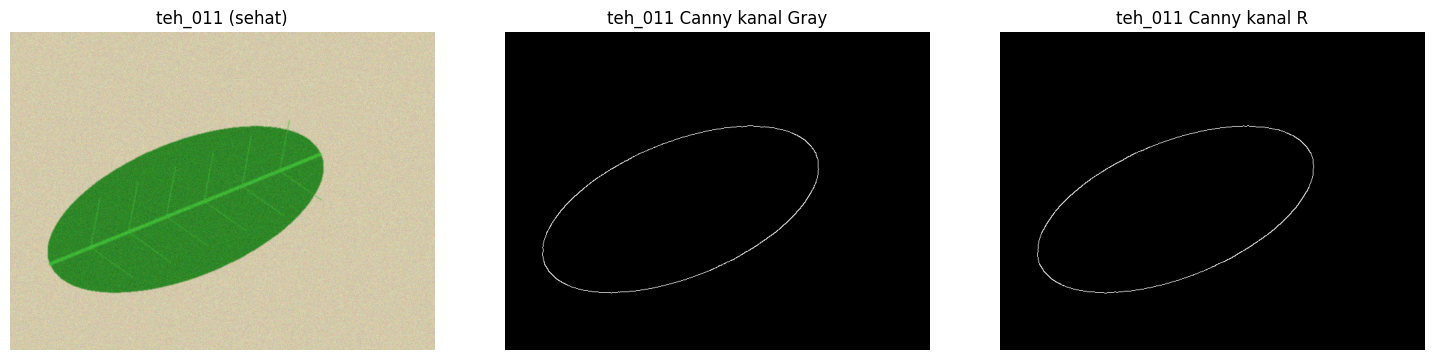

In [15]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    D = DATA[d.nama_file]
    dalam = cv2.erode(D["md"], np.ones((7, 7), np.uint8)) > 0       # bagian dalam daun (tanpa tepi)
    for kn, g in {"Gray": cv2.cvtColor(D["pra"], cv2.COLOR_BGR2GRAY), "R": D["pra"][:, :, 2]}.items():
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kn, int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e); judul.append(f"teh_011 Canny kanal {kn}")
sehat = pd.DataFrame(baris, columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"])
tab_sehat = sehat.pivot_table(index="kondisi", columns="kanal", values="piksel_tepi_di_dalam_daun").reindex(URUTAN).round(1)
print("Piksel tepi Canny di dalam daun sehat (rerata per kondisi)"); display(tab_sehat)
tab_sehat.to_csv("../hasil/p5_sehat_tepi_palsu.csv")
tampil([DATA["teh_011.png"]["img"]] + panel, ["teh_011 (sehat)"] + judul, ukuran=(15, 3.6))
plt.savefig("../hasil/p5_sehat_teh011.png", dpi=120); plt.show()

### Langkah 2.6 Keputusan pemakaian tepi (Tabel 8)
Cell berikut hanya menyediakan angka bukti. Tabel 8 diisi sendiri di laporan, dengan merujuk tabel dan gambar di atas.

In [16]:
# Bukti tambahan untuk Tabel 8: recall dipisah (batas daun vs batas bercak), presisi gabungan, dan waktu
baris = []
for _, d in berbercak.iterrows():
    D = DATA[d.nama_file]
    g = D["pra"][:, :, 2]
    e = tepi_canny(g)
    baris.append([d.kondisi_cahaya, d.kelas, skor_tepi(e, D["ac"])[0],
                  skor_tepi(e, D["ac_daun"])[1], skor_tepi(e, D["ac_bercak"])[1]])
bukti = pd.DataFrame(baris, columns=["kondisi", "kelas", "P_gabungan", "R_batas_daun", "R_batas_bercak"])
print("Canny 30/90 sigma 2, kanal R sesudah praproses")
display(bukti.groupby("kondisi")[["P_gabungan", "R_batas_daun", "R_batas_bercak"]].mean().reindex(URUTAN).round(3))
display(bukti.groupby("kelas")[["P_gabungan", "R_batas_daun", "R_batas_bercak"]].mean().round(3))

g = DATA["teh_041.png"]["pra"][:, :, 2]
t0 = time.perf_counter()
for _ in range(50): tepi_canny(g)
print(f"Waktu Canny per citra 640x480: {1000 * (time.perf_counter() - t0) / 50:.2f} ms")
bukti.to_csv("../hasil/p5_bukti_keputusan.csv", index=False)

Canny 30/90 sigma 2, kanal R sesudah praproses


,P_gabungan,R_batas_daun,R_batas_bercak
kondisi,,,
normal,0.984,0.995,0.981
gelap,0.984,0.995,0.990
terang,0.984,0.990,0.972
kontras_rendah,0.999,0.990,0.199
bayangan,0.979,0.995,0.980


,P_gabungan,R_batas_daun,R_batas_bercak
kelas,,,
berat,0.976,0.987,0.818
ringan,0.997,0.999,0.831


Waktu Canny per citra 640x480: 3.12 ms
